In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt



In [2]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression



In [3]:
try:
    df = pd.read_csv("/home/patel-krish/anaconda3/BrainyBeam/heart.csv")
except FileNotFoundError:
    df = pd.read_csv("/home/patel-krish/anaconda3/BrainyBeam/heart.csv")



In [4]:

df = df.drop_duplicates()
df = df.dropna(subset=["target"])

X = df.drop(columns=["target"])
y = df["target"].astype(int)


X = X.apply(pd.to_numeric, errors="coerce")


X = X.dropna(axis=1, how="all")

print("Dataset shape:", X.shape)
print("\nTarget distribution:")
print(y.value_counts())

Dataset shape: (302, 13)

Target distribution:
target
1    164
0    138
Name: count, dtype: int64


In [5]:
X_train_temp, X_test, y_train_temp, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train, X_temp, y_train, y_temp = train_test_split(
    X_train_temp,
    y_train_temp,
    test_size=0.25,
    random_state=42,
    stratify=y_train_temp
)

X_calibration, X_validation, y_calibration, y_validation = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training samples:", len(X_train))
print("Calibration samples:", len(X_calibration))
print("Validation samples:", len(X_validation))
print("Testing samples:", len(X_test))

Training samples: 180
Calibration samples: 30
Validation samples: 31
Testing samples: 61


In [6]:
# Handle missing values using training data only
imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)
X_calibration_imputed = imputer.transform(X_calibration)
X_validation_imputed = imputer.transform(X_validation)
X_test_imputed = imputer.transform(X_test)

# Train Random Forest
model = RandomForestClassifier(
    n_estimators=150,
    max_depth=8,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train_imputed, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [7]:
# Generate probabilities for the positive class
calibration_probabilities = model.predict_proba(
    X_calibration_imputed
)[:, 1]

validation_probabilities = model.predict_proba(
    X_validation_imputed
)[:, 1]

test_probabilities = model.predict_proba(
    X_test_imputed
)[:, 1]

# Original classification threshold
original_threshold = 0.50

original_predictions = (
    test_probabilities >= original_threshold
).astype(int)

print("Original threshold:", original_threshold)
print("Test predictions generated.")

Original threshold: 0.5
Test predictions generated.


Original Confusion Matrix:
[[21  7]
 [ 5 28]]

True Negatives: 21
False Positives: 7
False Negatives: 5
True Positives: 28


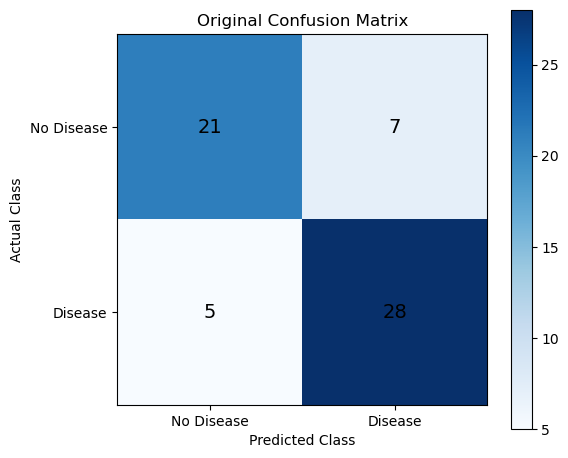

In [8]:
def manual_confusion_matrix(actual, predicted):

    actual = np.array(actual)
    predicted = np.array(predicted)

    tn = 0
    fp = 0
    fn = 0
    tp = 0

    for i in range(len(actual)):

        if actual[i] == 0 and predicted[i] == 0:
            tn += 1

        elif actual[i] == 0 and predicted[i] == 1:
            fp += 1

        elif actual[i] == 1 and predicted[i] == 0:
            fn += 1

        elif actual[i] == 1 and predicted[i] == 1:
            tp += 1

    matrix = np.array([
        [tn, fp],
        [fn, tp]
    ])

    return matrix, tn, fp, fn, tp


cm, tn, fp, fn, tp = manual_confusion_matrix(
    y_test,
    original_predictions
)

print("Original Confusion Matrix:")
print(cm)

print("\nTrue Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

# Plot confusion matrix
plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap="Blues")

plt.title("Original Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks([0, 1], ["No Disease", "Disease"])
plt.yticks([0, 1], ["No Disease", "Disease"])

for i in range(2):
    for j in range(2):
        plt.text(
            j, i, cm[i, j],
            ha="center",
            va="center",
            fontsize=14
        )

plt.colorbar()
plt.tight_layout()
plt.show()

In [9]:
def calculate_manual_metrics(tn, fp, fn, tp):

    accuracy = (tp + tn) / max(tp + tn + fp + fn, 1)

    precision = tp / max(tp + fp, 1)

    recall = tp / max(tp + fn, 1)

    specificity = tn / max(tn + fp, 1)

    f1 = (
        2 * precision * recall /
        max(precision + recall, 1e-10)
    )

    f2 = (
        5 * precision * recall /
        max(4 * precision + recall, 1e-10)
    )

    return {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "Specificity": specificity,
        "F1 Score": f1,
        "F2 Score": f2
    }


original_metrics = calculate_manual_metrics(
    tn, fp, fn, tp
)

print("ORIGINAL MODEL PERFORMANCE")

for metric, value in original_metrics.items():
    print(metric, ":", round(value, 4))

ORIGINAL MODEL PERFORMANCE
Accuracy : 0.8033
Precision : 0.8
Recall : 0.8485
Specificity : 0.75
F1 Score : 0.8235
F2 Score : 0.8383


In [10]:
# Create a test results DataFrame
misclassified_df = X_test.copy()

misclassified_df["Actual"] = np.array(y_test)
misclassified_df["Predicted"] = original_predictions
misclassified_df["Predicted_Probability"] = test_probabilities

# Identify errors
false_positives = misclassified_df[
    (misclassified_df["Actual"] == 0) &
    (misclassified_df["Predicted"] == 1)
]

false_negatives = misclassified_df[
    (misclassified_df["Actual"] == 1) &
    (misclassified_df["Predicted"] == 0)
]

print("FALSE POSITIVE EXAMPLES")
display(false_positives)

print("\nFALSE NEGATIVE EXAMPLES")
display(false_negatives)

print("\nTotal false positives:", len(false_positives))
print("Total false negatives:", len(false_negatives))

FALSE POSITIVE EXAMPLES


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,Actual,Predicted,Predicted_Probability
65,59,1,3,170,288,0,0,159,0,0.2,1,0,3,0,1,0.652658
58,67,1,2,152,212,0,0,150,0,0.8,1,0,3,0,1,0.743248
42,61,0,0,130,330,0,0,169,0,0.0,2,0,2,0,1,0.864646
258,38,1,3,120,231,0,1,182,1,3.8,1,0,3,0,1,0.700000
323,66,1,1,160,246,0,1,120,1,0.0,1,3,1,0,1,0.586667
35,46,1,2,150,231,0,1,147,0,3.6,1,0,2,0,1,0.697874
449,52,1,0,112,230,0,1,160,0,0.0,2,1,2,0,1,0.588076



FALSE NEGATIVE EXAMPLES


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,Actual,Predicted,Predicted_Probability
377,64,0,0,130,303,0,1,122,0,2.0,1,2,2,1,0,0.194877
111,53,1,0,142,226,0,0,111,1,0.0,2,0,3,1,0,0.200000
495,59,1,0,135,234,0,1,161,0,0.5,1,0,3,1,0,0.305921
38,64,1,0,128,263,0,1,105,1,0.2,1,1,3,1,0,0.073333
36,51,1,3,125,213,0,0,125,1,1.4,2,1,2,1,0,0.475300



Total false positives: 7
Total false negatives: 5


FEATURE PATTERN ANALYSIS


Error_Type,Correct,False Negative,False Positive
age,54.979592,58.20,55.571429
sex,0.673469,0.80,0.857143
cp,0.816327,0.60,1.571429
trestbps,131.489796,132.00,142.000000
chol,239.938776,247.80,252.571429
fbs,0.244898,0.00,0.000000
restecg,0.469388,0.60,0.571429
thalach,145.102041,124.80,155.285714
exang,0.448980,0.60,0.285714
oldpeak,1.277551,0.82,1.200000


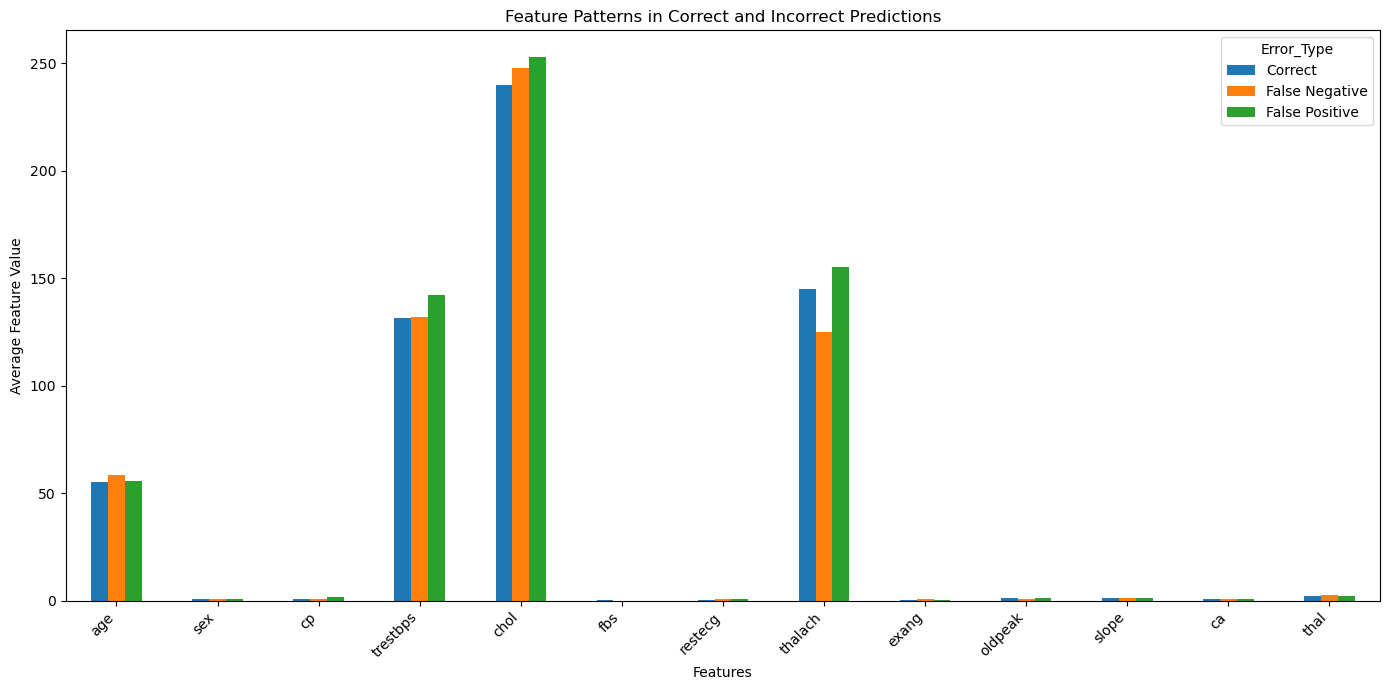

In [11]:
# Add classification category
misclassified_df["Error_Type"] = "Correct"

misclassified_df.loc[
    (misclassified_df["Actual"] == 0) &
    (misclassified_df["Predicted"] == 1),
    "Error_Type"
] = "False Positive"

misclassified_df.loc[
    (misclassified_df["Actual"] == 1) &
    (misclassified_df["Predicted"] == 0),
    "Error_Type"
] = "False Negative"

# Calculate feature averages by error type
feature_columns = X.columns.tolist()

pattern_analysis = misclassified_df.groupby(
    "Error_Type"
)[feature_columns].mean().T

print("FEATURE PATTERN ANALYSIS")
display(pattern_analysis)

# Visualize feature differences
if len(pattern_analysis.columns) > 1:

    pattern_analysis.plot(
        kind="bar",
        figsize=(14, 7)
    )

    plt.title("Feature Patterns in Correct and Incorrect Predictions")
    plt.xlabel("Features")
    plt.ylabel("Average Feature Value")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

AVERAGE PREDICTED PROBABILITY
False Positive: 0.6905
False Negative: 0.2499
Correct Predictions: 0.5301


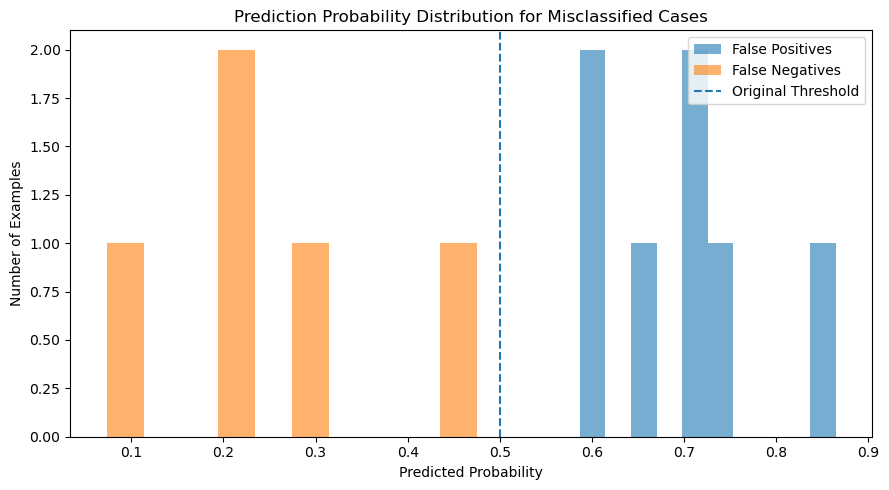

In [12]:
# Separate probabilities for each prediction group
fp_probabilities = false_positives["Predicted_Probability"]
fn_probabilities = false_negatives["Predicted_Probability"]

correct_predictions = misclassified_df[
    misclassified_df["Error_Type"] == "Correct"
]

print("AVERAGE PREDICTED PROBABILITY")

print(
    "False Positive:",
    round(fp_probabilities.mean(), 4)
    if len(fp_probabilities) else "No false positives"
)

print(
    "False Negative:",
    round(fn_probabilities.mean(), 4)
    if len(fn_probabilities) else "No false negatives"
)

print(
    "Correct Predictions:",
    round(correct_predictions["Predicted_Probability"].mean(), 4)
    if len(correct_predictions) else "No correct predictions"
)

# Plot probability distributions
plt.figure(figsize=(9, 5))

if len(fp_probabilities):
    plt.hist(
        fp_probabilities,
        bins=10,
        alpha=0.6,
        label="False Positives"
    )

if len(fn_probabilities):
    plt.hist(
        fn_probabilities,
        bins=10,
        alpha=0.6,
        label="False Negatives"
    )

plt.axvline(
    0.50,
    linestyle="--",
    label="Original Threshold"
)

plt.title("Prediction Probability Distribution for Misclassified Cases")
plt.xlabel("Predicted Probability")
plt.ylabel("Number of Examples")
plt.legend()
plt.tight_layout()
plt.show()

In [13]:
# Avoid infinite values when converting probabilities to logits
epsilon = 1e-6

calibration_logits = np.log(
    np.clip(
        calibration_probabilities,
        epsilon,
        1 - epsilon
    ) /
    (
        1 - np.clip(
            calibration_probabilities,
            epsilon,
            1 - epsilon
        )
    )
).reshape(-1, 1)

# Train sigmoid calibration model
calibrator = LogisticRegression(
    random_state=42
)

calibrator.fit(
    calibration_logits,
    y_calibration
)

# Convert validation probabilities to logits
validation_logits = np.log(
    np.clip(
        validation_probabilities,
        epsilon,
        1 - epsilon
    ) /
    (
        1 - np.clip(
            validation_probabilities,
            epsilon,
            1 - epsilon
        )
    )
).reshape(-1, 1)

# Calibrated validation probabilities
calibrated_validation_probabilities = calibrator.predict_proba(
    validation_logits
)[:, 1]

print("Probability calibration completed.")

Probability calibration completed.


Best threshold: 0.13

Validation performance at selected threshold:


,Threshold,Precision,Recall,Specificity,F1 Score,F2 Score
3,0.13,0.62963,1.0,0.285714,0.772727,0.894737


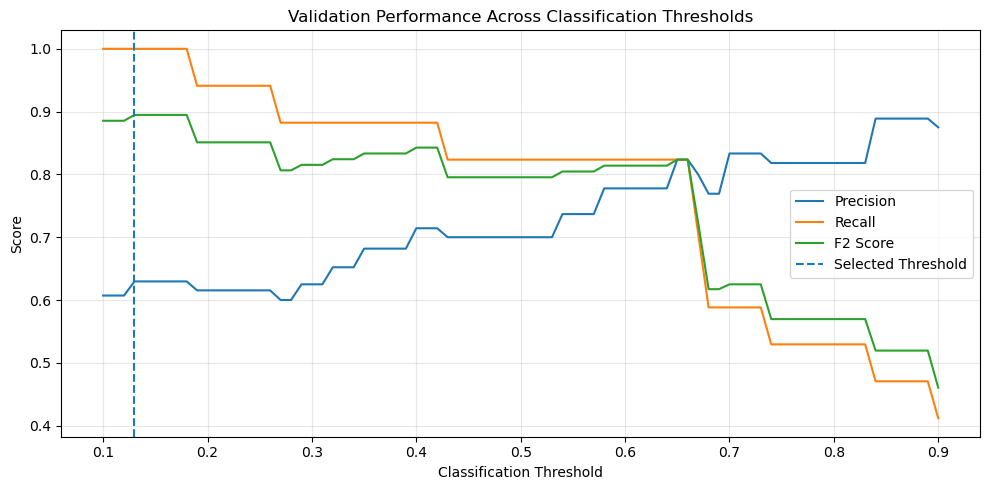

In [14]:
threshold_results = []

threshold_values = np.arange(
    0.10,
    0.91,
    0.01
)

for threshold in threshold_values:

    validation_predictions = (
        calibrated_validation_probabilities >= threshold
    ).astype(int)

    matrix, tn_v, fp_v, fn_v, tp_v = manual_confusion_matrix(
        y_validation,
        validation_predictions
    )

    metrics = calculate_manual_metrics(
        tn_v, fp_v, fn_v, tp_v
    )

    threshold_results.append({
        "Threshold": threshold,
        "Precision": metrics["Precision"],
        "Recall": metrics["Recall"],
        "Specificity": metrics["Specificity"],
        "F1 Score": metrics["F1 Score"],
        "F2 Score": metrics["F2 Score"]
    })

threshold_df = pd.DataFrame(threshold_results)

# Select threshold with the highest validation F2 score
best_row = threshold_df.loc[
    threshold_df["F2 Score"].idxmax()
]

best_threshold = best_row["Threshold"]

print("Best threshold:", round(best_threshold, 2))
print("\nValidation performance at selected threshold:")
display(best_row.to_frame().T)

# Plot threshold performance
plt.figure(figsize=(10, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F2 Score"],
    label="F2 Score"
)

plt.axvline(
    best_threshold,
    linestyle="--",
    label="Selected Threshold"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Validation Performance Across Classification Thresholds")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

ADJUSTED CONFUSION MATRIX
[[ 8 20]
 [ 1 32]]

True Negatives: 8
False Positives: 20
False Negatives: 1
True Positives: 32


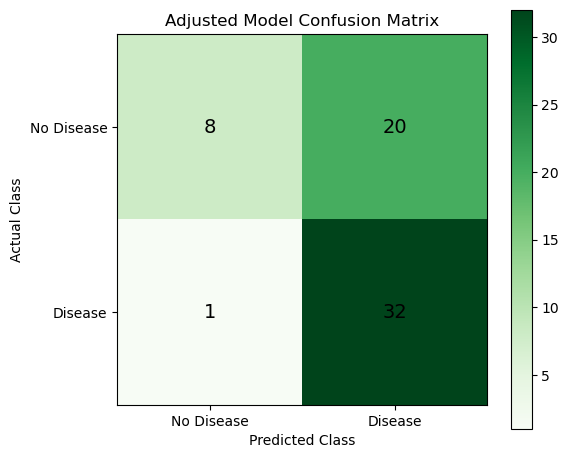

In [15]:
# Convert original test probabilities into logits
test_logits = np.log(
    np.clip(
        test_probabilities,
        epsilon,
        1 - epsilon
    ) /
    (
        1 - np.clip(
            test_probabilities,
            epsilon,
            1 - epsilon
        )
    )
).reshape(-1, 1)

# Calibrate test probabilities
calibrated_test_probabilities = calibrator.predict_proba(
    test_logits
)[:, 1]

# Apply selected threshold
adjusted_predictions = (
    calibrated_test_probabilities >= best_threshold
).astype(int)

# Manually calculate adjusted confusion matrix
adjusted_cm, tn_new, fp_new, fn_new, tp_new = manual_confusion_matrix(
    y_test,
    adjusted_predictions
)

print("ADJUSTED CONFUSION MATRIX")
print(adjusted_cm)

print("\nTrue Negatives:", tn_new)
print("False Positives:", fp_new)
print("False Negatives:", fn_new)
print("True Positives:", tp_new)

# Plot adjusted confusion matrix
plt.figure(figsize=(6, 5))
plt.imshow(adjusted_cm, cmap="Greens")

plt.title("Adjusted Model Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks([0, 1], ["No Disease", "Disease"])
plt.yticks([0, 1], ["No Disease", "Disease"])

for i in range(2):
    for j in range(2):
        plt.text(
            j, i, adjusted_cm[i, j],
            ha="center",
            va="center",
            fontsize=14
        )

plt.colorbar()
plt.tight_layout()
plt.show()

MODEL PERFORMANCE COMPARISON


,Metric,Original Model,Adjusted Model,Difference
0,Accuracy,0.8033,0.6557,-0.1475
1,Precision,0.8000,0.6154,-0.1846
2,Recall,0.8485,0.9697,0.1212
3,Specificity,0.7500,0.2857,-0.4643
4,F1 Score,0.8235,0.7529,-0.0706
5,F2 Score,0.8383,0.8696,0.0312


,Error Type,Original Model,Adjusted Model
0,False Positives,7,20
1,False Negatives,5,1


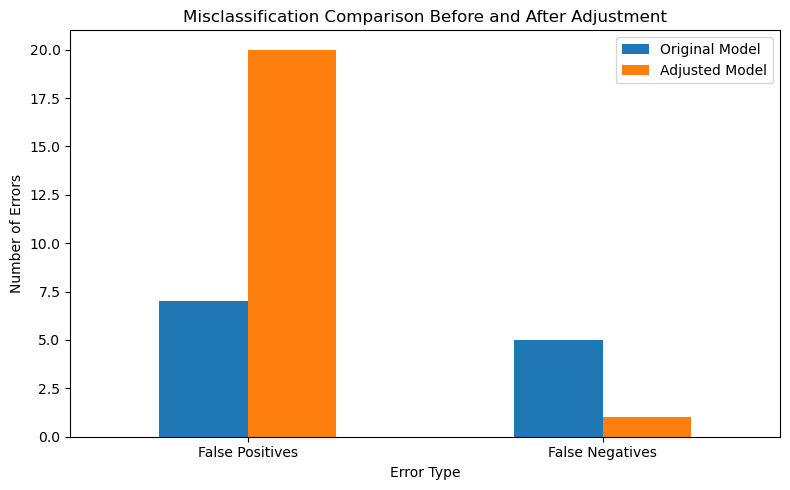

In [16]:
adjusted_metrics = calculate_manual_metrics(
    tn_new, fp_new, fn_new, tp_new
)

comparison_df = pd.DataFrame({
    "Metric": list(original_metrics.keys()),
    "Original Model": list(original_metrics.values()),
    "Adjusted Model": list(adjusted_metrics.values())
})

comparison_df["Difference"] = (
    comparison_df["Adjusted Model"] -
    comparison_df["Original Model"]
)

print("MODEL PERFORMANCE COMPARISON")
display(comparison_df.round(4))

# Compare false positives and false negatives
error_comparison = pd.DataFrame({
    "Error Type": ["False Positives", "False Negatives"],
    "Original Model": [fp, fn],
    "Adjusted Model": [fp_new, fn_new]
})

display(error_comparison)

error_comparison.plot(
    x="Error Type",
    kind="bar",
    figsize=(8, 5)
)

plt.title("Misclassification Comparison Before and After Adjustment")
plt.ylabel("Number of Errors")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [17]:
# Manual Brier score calculation
def manual_brier_score(actual, probabilities):

    actual = np.array(actual)
    probabilities = np.array(probabilities)

    return np.mean(
        (probabilities - actual) ** 2
    )


original_brier = manual_brier_score(
    y_test,
    test_probabilities
)

adjusted_brier = manual_brier_score(
    y_test,
    calibrated_test_probabilities
)

print("Original Brier Score:", round(original_brier, 4))
print("Adjusted Brier Score:", round(adjusted_brier, 4))

if adjusted_brier < original_brier:
    print("Probability calibration improved on the test set.")
else:
    print("Probability calibration did not improve on the test set.")

Original Brier Score: 0.1438
Adjusted Brier Score: 0.1435
Probability calibration improved on the test set.


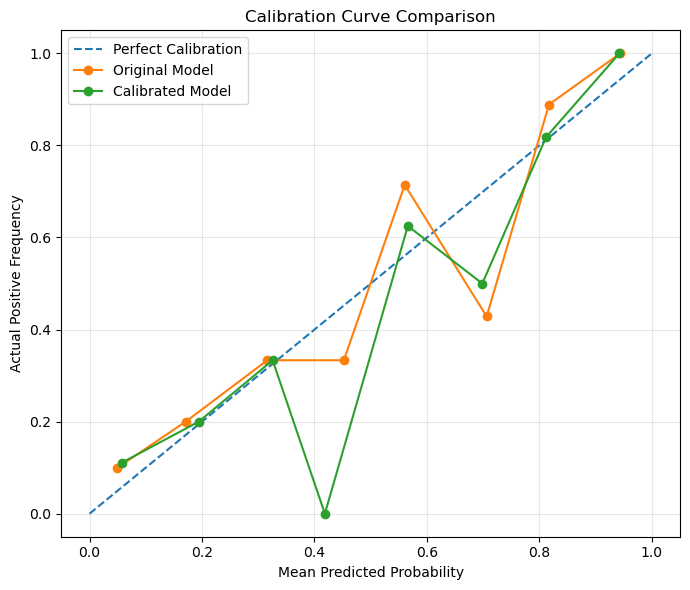

In [18]:
def calculate_calibration_points(actual, probabilities, bins=8):

    actual = np.array(actual)
    probabilities = np.array(probabilities)

    bin_edges = np.linspace(0, 1, bins + 1)

    mean_predictions = []
    actual_frequencies = []

    for i in range(bins):

        if i == bins - 1:
            mask = (
                (probabilities >= bin_edges[i]) &
                (probabilities <= bin_edges[i + 1])
            )
        else:
            mask = (
                (probabilities >= bin_edges[i]) &
                (probabilities < bin_edges[i + 1])
            )

        if np.sum(mask) > 0:

            mean_predictions.append(
                probabilities[mask].mean()
            )

            actual_frequencies.append(
                actual[mask].mean()
            )

    return mean_predictions, actual_frequencies


original_mean, original_frequency = calculate_calibration_points(
    y_test,
    test_probabilities
)

adjusted_mean, adjusted_frequency = calculate_calibration_points(
    y_test,
    calibrated_test_probabilities
)

plt.figure(figsize=(7, 6))

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.plot(
    original_mean,
    original_frequency,
    marker="o",
    label="Original Model"
)

plt.plot(
    adjusted_mean,
    adjusted_frequency,
    marker="o",
    label="Calibrated Model"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Actual Positive Frequency")
plt.title("Calibration Curve Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [19]:
# Create a report with the measured results
report = []

report.append("# False Positive and False Negative Analysis")
report.append("")
report.append("## 1. Original Model")
report.append(f"- True Negatives: {tn}")
report.append(f"- False Positives: {fp}")
report.append(f"- False Negatives: {fn}")
report.append(f"- True Positives: {tp}")
report.append(f"- Original threshold: {original_threshold}")
report.append("")

report.append("## 2. Adjusted Model")
report.append(f"- True Negatives: {tn_new}")
report.append(f"- False Positives: {fp_new}")
report.append(f"- False Negatives: {fn_new}")
report.append(f"- True Positives: {tp_new}")
report.append(f"- Selected threshold: {best_threshold:.2f}")
report.append("")

report.append("## 3. Performance Comparison")
report.append(comparison_df.round(4).to_string(index=False))
report.append("")

report.append("## 4. Probability Calibration")
report.append(f"- Original Brier score: {original_brier:.4f}")
report.append(f"- Adjusted Brier score: {adjusted_brier:.4f}")
report.append("")

report.append("## 5. Misclassification Findings")
report.append(
    f"- Number of false positive cases: {len(false_positives)}"
)
report.append(
    f"- Number of false negative cases: {len(false_negatives)}"
)
report.append(
    "- Feature averages were compared across correctly classified, "
    "false-positive, and false-negative cases."
)
report.append("")

report.append("## 6. Conclusion")
report.append(
    "Probability calibration and threshold adjustment were evaluated "
    "using separate calibration and validation datasets. Final results "
    "were measured on an untouched test dataset. Improvements should "
    "only be claimed when the corresponding test metrics actually improve."
)
report.append("")

report.append("## 7. Limitations")
report.append(
    "- Misclassification patterns do not establish medical causes."
)
report.append(
    "- Calibration results can be unstable with a small dataset."
)
report.append(
    "- Threshold selection depends on the relative cost of false positives "
    "and false negatives."
)
report.append(
    "- This model is for educational analysis and is not a clinical diagnostic tool."
)

with open(
    "false_positive_false_negative_analysis.md",
    "w",
    encoding="utf-8"
) as file:
    file.write("\n".join(report))

print("Final analysis report generated successfully.")
print("File: false_positive_false_negative_analysis.md")

Final analysis report generated successfully.
File: false_positive_false_negative_analysis.md


In [20]:
# Save misclassified records
false_positives.to_csv(
    "false_positive_examples.csv",
    index=False
)

false_negatives.to_csv(
    "false_negative_examples.csv",
    index=False
)

# Save model comparison
comparison_df.to_csv(
    "model_calibration_comparison.csv",
    index=False
)

# Save threshold evaluation
threshold_df.to_csv(
    "threshold_evaluation.csv",
    index=False
)

print("All analysis files saved successfully.")

All analysis files saved successfully.
